# Sentiment Analysis: US Airline Tweets
**Oasis Infobyte SIP — Data Analytics L1 Task 4** · Steven Manuel Rios

Dataset: **Twitter US Airline Sentiment** (Figure Eight / Kaggle): 14,640 tweets labelled positive, neutral or negative.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
df = pd.read_csv("data/Tweets.csv")[["text", "airline_sentiment", "airline"]]
print(df.shape); print(df.isnull().sum()); df["airline_sentiment"].value_counts()

(14640, 3)
text                 0
airline_sentiment    0
airline              0
dtype: int64


airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

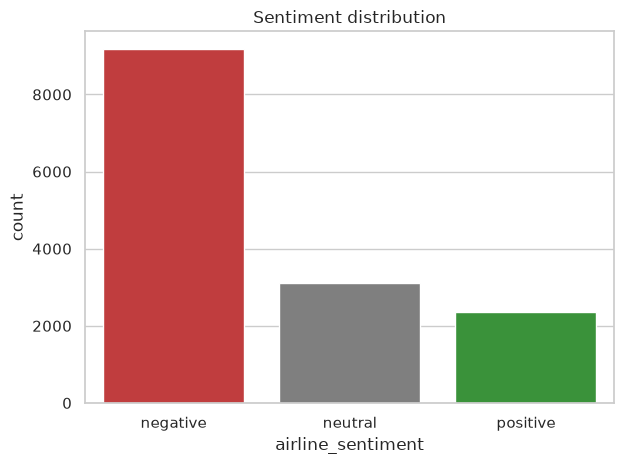

In [3]:
order = ["negative", "neutral", "positive"]
sns.countplot(data=df, x="airline_sentiment", order=order, palette=["#d62728", "#7f7f7f", "#2ca02c"]); plt.title("Sentiment distribution"); save("distribution")

The classes are **imbalanced**: 63% negative, 21% neutral, 16% positive. Macro-averaged F1 is reported alongside accuracy for that reason.

## Preprocessing pipeline
lowercase → remove @mentions, URLs, punctuation and digits → tokenise → remove stopwords (keeping negations such as *not* and *no*) → WordNet lemmatisation.

In [4]:
import re, nltk
for p, loc in [("stopwords", "corpora/stopwords"), ("wordnet", "corpora/wordnet"), ("punkt_tab", "tokenizers/punkt_tab")]:
    try: nltk.data.find(loc)
    except LookupError: nltk.download(p, quiet=True)
from nltk.corpus import stopwords; from nltk.stem import WordNetLemmatizer; from nltk.tokenize import word_tokenize
stop = set(stopwords.words("english")) - {"not", "no", "nor", "don't", "won't", "can't"}; lem = WordNetLemmatizer()
def clean(t):
    t = re.sub(r"@\w+|http\S+|[^a-z\s]", " ", t.lower())
    return " ".join(lem.lemmatize(w) for w in word_tokenize(t) if w not in stop and len(w) > 1)
df["clean"] = df["text"].apply(clean); df[["text", "clean"]].head()

,text,clean
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials t...,plus added commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing


## TF-IDF
**TF-IDF** (term frequency × inverse document frequency) turns each tweet into a sparse vector. A word scores high when it is frequent in *this* tweet but rare across the corpus. Ubiquitous words like *flight* are down-weighted, and distinctive words like *rude* or *awesome* are emphasised. Unigrams and bigrams are used so phrases like *not happy* are captured.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(df["clean"], df["airline_sentiment"], test_size=.2, stratify=df["airline_sentiment"], random_state=42)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True); Xtr_v = vec.fit_transform(Xtr); Xte_v = vec.transform(Xte); Xtr_v.shape

(11712, 13907)

===== Naive Bayes =====
               precision    recall  f1-score   support

    negative      0.754     0.971     0.849      1835
     neutral      0.695     0.345     0.461       620
    positive      0.838     0.459     0.593       473

    accuracy                          0.755      2928
   macro avg      0.762     0.592     0.634      2928
weighted avg      0.755     0.755     0.725      2928



===== Logistic Regression =====
               precision    recall  f1-score   support

    negative      0.876     0.832     0.853      1835
     neutral      0.562     0.656     0.606       620
    positive      0.698     0.679     0.688       473

    accuracy                          0.770      2928
   macro avg      0.712     0.722     0.716      2928
weighted avg      0.780     0.770     0.774      2928

===== Linear SVM =====
               precision    recall  f1-score   support

    negative      0.861     0.876     0.868      1835
     neutral      0.600     0.613     0.607       620
    positive      0.731     0.660     0.693       473

    accuracy                          0.786      2928
   macro avg      0.731     0.716     0.723      2928
weighted avg      0.785     0.786     0.785      2928



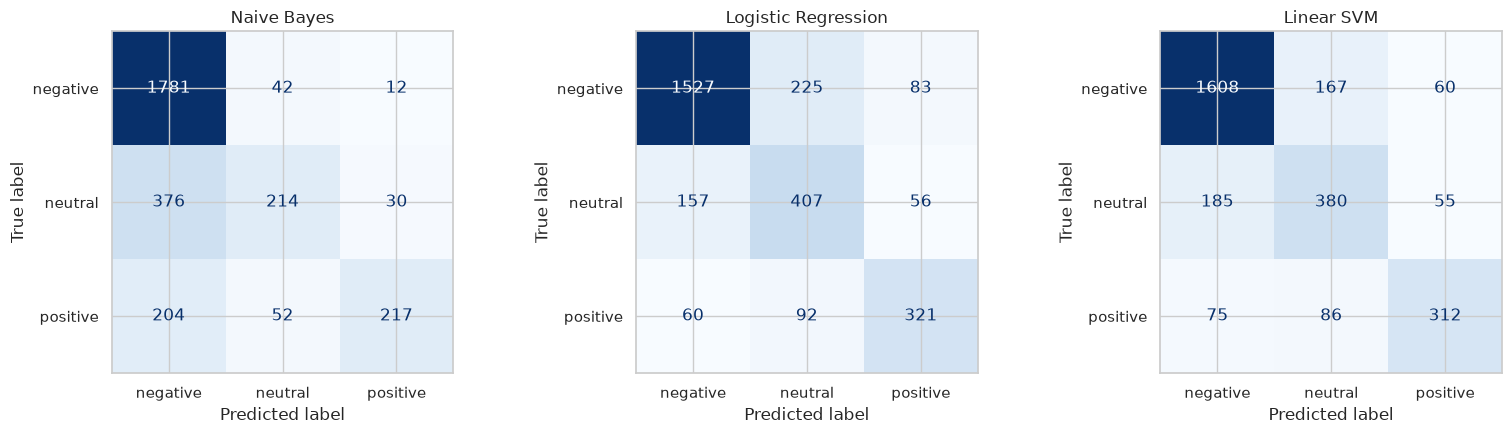

,accuracy,macro F1
Naive Bayes,0.755,0.634
Logistic Regression,0.770,0.716
Linear SVM,0.786,0.723


In [6]:
from sklearn.naive_bayes import MultinomialNB; from sklearn.svm import LinearSVC; from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay
models = {"Naive Bayes": MultinomialNB(alpha=.3), "Logistic Regression": LogisticRegression(max_iter=2000, C=4, class_weight="balanced"), "Linear SVM": LinearSVC(C=.5, class_weight="balanced")}
res = {}; fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (n, m) in zip(ax, models.items()):
    p = m.fit(Xtr_v, ytr).predict(Xte_v); res[n] = p
    print(f"===== {n} =====\n", classification_report(yte, p, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(yte, p, labels=order), display_labels=order).plot(ax=a, colorbar=False, cmap="Blues"); a.set_title(n)
save("confusion_matrices")
summary = pd.DataFrame({n: {"accuracy": accuracy_score(yte, p), "macro F1": f1_score(yte, p, average="macro")} for n, p in res.items()}).T.round(3); summary

## Word clouds per sentiment

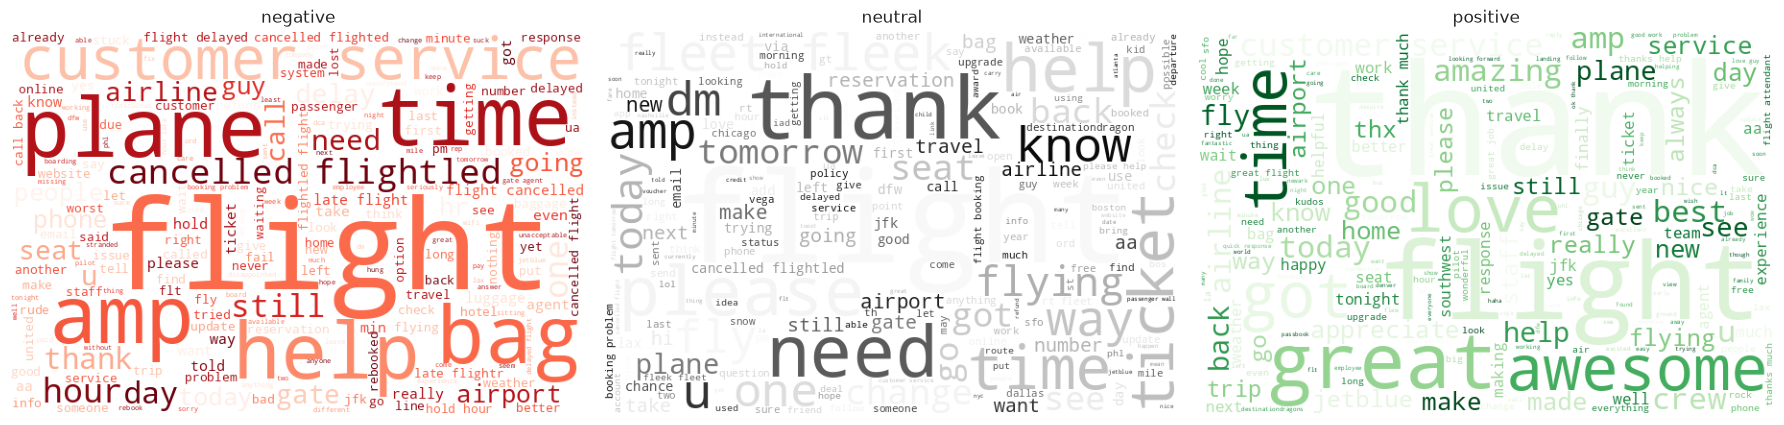

In [7]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, s, cm in zip(ax, order, ["Reds", "Greys", "Greens"]):
    a.imshow(WordCloud(width=600, height=400, background_color="white", colormap=cm).generate(" ".join(df.loc[df.airline_sentiment == s, "clean"]))); a.axis("off"); a.set_title(s)
save("wordclouds")

## Error analysis

In [8]:
best = summary["macro F1"].idxmax(); p = res[best]
err = pd.DataFrame({"text": df.loc[Xte.index, "text"].values, "true": yte.values, "pred": p})
err = err[err.true != err.pred].sample(5, random_state=3); pd.set_option("display.max_colwidth", 200); print("Best model:", best); err

Best model: Linear SVM


,text,true,pred
2741,"@SouthwestAir wanting a ⭐️ for the ✈️ finding the gate. No apology or exp. All good, I'm sure connecting flight leaving SAC will be chill!",negative,neutral
2179,@SouthwestAir Southwest is scheduled to fly to Costa Rica on March 7 but I can't book it online. When will this be available?,negative,neutral
616,@united Boeing 777 Star Alliance short finals @Heathrowairport 27L on an amazing winters morning #777 #Avgeek http://t.co/owMaXOyEhZ,positive,neutral
1742,@AmericanAir don't see response!,negative,positive
1329,@JetBlue yes he and all the princesses. Trying to get to the #glassslipperchallenge at WDW.,neutral,negative


## Error analysis discussion
* **Sarcasm:** "All good, I'm sure connecting flight … will be chill!" is negative, but its words are positive or neutral.
* **Complaint phrased as a question:** "I can't book it online. When will this be available?" has no explicit negative words, so it looks neutral.
* **Emoji and hashtag sentiment:** "amazing winters morning #Avgeek" is enthusiasm the model reads as neutral, because the emoji and hashtags are stripped in preprocessing.
* **Very short, context-dependent text:** "don't see response!" gives the model too little signal.
* **Label noise:** some gold labels are debatable (the princess tweet), which caps achievable accuracy.

## Conclusion
**Linear SVM performs best** (accuracy 78.6%, macro F1 0.723), narrowly ahead of Logistic Regression (macro F1 0.716). Naive Bayes reaches 75.5% accuracy but has poor neutral and positive recall (0.35 / 0.46) because it is biased towards the majority class. Neutral is the hardest class for every model.

**Real-world use:** an airline social-care dashboard that triages incoming tweets in real time and sends negative ones to support agents first, and that tracks sentiment per airline or route over time as a customer-satisfaction KPI.